# Standalone global H1-H12 XGBoost training

This Colab notebook needs only `horizon_training_dataset.csv`. It performs chronological splitting, categorical encoding, training, validation, testing, and artifact saving without importing project Python scripts.

In [1]:
%pip install -q pandas scikit-learn xgboost joblib

## Mount Drive and configure paths

Upload the CSV to `MyDrive/demand-forecasting/dataset/horizon_training_dataset.csv`. Change `DRIVE_DATA_FILE` below if you use another location.

In [2]:
import json
import platform
import shutil
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
import xgboost
from google.colab import drive

drive.mount("/content/drive")

DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/demand-forecasting")
DRIVE_DATA_FILE = DRIVE_PROJECT_DIR / "Dataset" / "horizon_training_dataset.csv"
DRIVE_ARTIFACT_DIR = DRIVE_PROJECT_DIR / "artifacts"
LOCAL_ARTIFACT_DIR = Path("/content/xgboost_artifacts")

if not DRIVE_DATA_FILE.exists():
    raise FileNotFoundError(f"Upload horizon_training_dataset.csv to: {DRIVE_DATA_FILE}")

print(f"Dataset: {DRIVE_DATA_FILE}")
print(f"Local output: {LOCAL_ARTIFACT_DIR}")
print(f"Drive output: {DRIVE_ARTIFACT_DIR}")

Mounted at /content/drive
Dataset: /content/drive/MyDrive/demand-forecasting/Dataset/horizon_training_dataset.csv
Local output: /content/xgboost_artifacts
Drive output: /content/drive/MyDrive/demand-forecasting/artifacts


## Load data and create chronological splits

The final three target months are the test set, the preceding three target months are validation, and all earlier target months are training.

In [3]:
TARGET_COLUMN = "future_demand_kg"
CATEGORICAL_FEATURES = ["crop", "location", "origin_season", "target_season"]
EXCLUDED_FEATURES = ["forecast_origin_month", "target_month", TARGET_COLUMN]
VALIDATION_MONTHS = 3
TEST_MONTHS = 3

data = pd.read_csv(
    DRIVE_DATA_FILE,
    parse_dates=["forecast_origin_month", "target_month"],
)

required = [
    "forecast_origin_month", "target_month", "forecast_horizon",
    *CATEGORICAL_FEATURES, TARGET_COLUMN,
]
missing = [column for column in required if column not in data.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")
if data[TARGET_COLUMN].isna().any():
    raise ValueError("Training data contains missing future targets.")

data = data.sort_values(["target_month", "forecast_origin_month"]).reset_index(drop=True)
final_month = data["target_month"].max().to_period("M").to_timestamp()
test_start = final_month - pd.DateOffset(months=TEST_MONTHS - 1)
validation_start = test_start - pd.DateOffset(months=VALIDATION_MONTHS)

train = data[data["target_month"] < validation_start].copy()
validation = data[data["target_month"].between(validation_start, test_start - pd.DateOffset(months=1))].copy()
test = data[data["target_month"] >= test_start].copy()

for name, split in {"train": train, "validation": validation, "test": test}.items():
    if split.empty:
        raise ValueError(f"{name} split is empty.")
    if set(split["forecast_horizon"].unique()) != set(range(1, 13)):
        raise ValueError(f"{name} split does not contain every H1-H12 horizon.")

if not (train["target_month"].max() < validation["target_month"].min() < test["target_month"].min()):
    raise ValueError("Chronological split boundaries overlap.")

print(f"Train: {len(train):,} rows, {train.target_month.min().date()} to {train.target_month.max().date()}")
print(f"Validation: {len(validation):,} rows, {validation.target_month.min().date()} to {validation.target_month.max().date()}")
print(f"Test: {len(test):,} rows, {test.target_month.min().date()} to {test.target_month.max().date()}")

Train: 19,170 rows, 2022-02-01 to 2025-06-01
Validation: 1,620 rows, 2025-07-01 to 2025-09-01
Test: 1,620 rows, 2025-10-01 to 2025-12-01


## Define preprocessing and XGBoost

Categorical values are one-hot encoded inside the saved pipeline. Numeric missing values use the training median.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

FEATURE_COLUMNS = [column for column in data.columns if column not in EXCLUDED_FEATURES]
NUMERIC_FEATURES = [column for column in FEATURE_COLUMNS if column not in CATEGORICAL_FEATURES]

unexpected_text = [column for column in NUMERIC_FEATURES if not pd.api.types.is_numeric_dtype(data[column])]
if unexpected_text:
    raise ValueError(f"Features need an encoding policy: {unexpected_text}")

def build_pipeline(device="cpu"):
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])
    preprocessor = ColumnTransformer(
        [
            ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
            ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    model = XGBRegressor(
        objective="reg:squarederror", n_estimators=500, learning_rate=0.03,
        max_depth=6, min_child_weight=3, subsample=0.85,
        colsample_bytree=0.85, reg_alpha=0.05, reg_lambda=1.0,
        tree_method="hist", eval_metric="mae", random_state=42,
        n_jobs=-1, device=device,
    )
    return Pipeline([("preprocessor", preprocessor), ("model", model)])

def split_xy(frame):
    return frame[FEATURE_COLUMNS].copy(), frame[TARGET_COLUMN].copy()

print(f"Features: {len(FEATURE_COLUMNS)} ({len(CATEGORICAL_FEATURES)} categorical, {len(NUMERIC_FEATURES)} numeric)")

Features: 58 (4 categorical, 54 numeric)


## Train, validate, refit, and test

Use `DEVICE = "cpu"` normally. Change it to `"cuda"` only when a Colab GPU runtime is enabled.

In [5]:
DEVICE = "cpu"

X_train, y_train = split_xy(train)
X_validation, y_validation = split_xy(validation)
X_test, y_test = split_xy(test)

validation_pipeline = build_pipeline(DEVICE)
validation_pipeline.fit(X_train, y_train)
validation_values = validation_pipeline.predict(X_validation)

train_validation = pd.concat([train, validation], ignore_index=True).sort_values("target_month")
X_train_validation, y_train_validation = split_xy(train_validation)
final_pipeline = build_pipeline(DEVICE)
final_pipeline.fit(X_train_validation, y_train_validation)
test_values = final_pipeline.predict(X_test)

print("Training complete.")

Training complete.


## Evaluate overall and by horizon

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

KEY_COLUMNS = ["forecast_origin_month", "target_month", "crop", "location", "forecast_horizon", TARGET_COLUMN]

def prediction_table(frame, values, split_name):
    output = frame[KEY_COLUMNS].copy()
    output["xgboost_prediction"] = values
    output["split"] = split_name
    output["absolute_error"] = (output[TARGET_COLUMN] - output["xgboost_prediction"]).abs()
    return output

def metric_values(frame):
    actual = frame[TARGET_COLUMN].to_numpy(dtype=float)
    predicted = frame["xgboost_prediction"].to_numpy(dtype=float)
    denominator = np.abs(actual).sum()
    return {
        "mae": mean_absolute_error(actual, predicted),
        "rmse": np.sqrt(mean_squared_error(actual, predicted)),
        "wape": np.abs(actual - predicted).sum() / denominator if denominator > 0 else np.nan,
        "r2": r2_score(actual, predicted),
    }

validation_predictions = prediction_table(validation, validation_values, "validation")
test_predictions = prediction_table(test, test_values, "test")
records = []
for split_name, predictions in [("validation", validation_predictions), ("test", test_predictions)]:
    records.append({"model": "xgboost", "split": split_name, "forecast_horizon": "overall", "rows": len(predictions), **metric_values(predictions)})
    for horizon, group in predictions.groupby("forecast_horizon"):
        records.append({"model": "xgboost", "split": split_name, "forecast_horizon": int(horizon), "rows": len(group), **metric_values(group)})
metrics = pd.DataFrame(records)
display(metrics)

,model,split,forecast_horizon,rows,mae,rmse,wape,r2
0,xgboost,validation,overall,1620,534.619676,712.303947,0.200107,0.552359
1,xgboost,validation,1,135,531.590450,716.435080,0.198973,0.547151
2,xgboost,validation,2,135,524.165303,714.216953,0.196194,0.549951
3,xgboost,validation,3,135,540.361494,724.645818,0.202256,0.536712
4,xgboost,validation,4,135,531.198288,712.324408,0.198826,0.552333
5,xgboost,validation,5,135,524.018606,705.209290,0.196139,0.561231
6,xgboost,validation,6,135,534.876624,714.133942,0.200203,0.550056
7,xgboost,validation,7,135,543.657553,718.161616,0.203489,0.544966
8,xgboost,validation,8,135,532.840947,710.968374,0.199441,0.554036
9,xgboost,validation,9,135,534.108123,705.115315,0.199915,0.561348


## Save locally and to Google Drive

In [7]:
local_model_dir = LOCAL_ARTIFACT_DIR / "models"
local_prediction_dir = LOCAL_ARTIFACT_DIR / "predictions"
local_report_dir = LOCAL_ARTIFACT_DIR / "reports"
for directory in [local_model_dir, local_prediction_dir, local_report_dir]:
    directory.mkdir(parents=True, exist_ok=True)

pipeline_file = local_model_dir / "global_xgboost_pipeline.joblib"
native_file = local_model_dir / "global_xgboost_model.json"
validation_file = local_prediction_dir / "xgboost_validation_predictions.csv"
test_file = local_prediction_dir / "xgboost_test_predictions.csv"
metrics_file = local_report_dir / "xgboost_metrics.csv"
metadata_file = local_report_dir / "xgboost_training_metadata.json"

joblib.dump(final_pipeline, pipeline_file)
final_pipeline.named_steps["model"].save_model(native_file)
validation_predictions.to_csv(validation_file, index=False)
test_predictions.to_csv(test_file, index=False)
metrics.to_csv(metrics_file, index=False)
metadata = {
    "model": "global_direct_multi_horizon_xgboost",
    "target": TARGET_COLUMN,
    "feature_columns": FEATURE_COLUMNS,
    "categorical_features": CATEGORICAL_FEATURES,
    "final_fit_data": "train + validation",
    "validation_prediction_model": "train only",
    "test_prediction_model": "train + validation",
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__, "joblib": joblib.__version__},
}
metadata_file.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

local_files = [pipeline_file, native_file, validation_file, test_file, metrics_file, metadata_file]
for source in local_files:
    relative = source.relative_to(LOCAL_ARTIFACT_DIR)
    destination = DRIVE_ARTIFACT_DIR / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

print("Saved locally:")
for path in local_files:
    print(path)
print(f"\nCopied to Google Drive: {DRIVE_ARTIFACT_DIR}")

Saved locally:
/content/xgboost_artifacts/models/global_xgboost_pipeline.joblib
/content/xgboost_artifacts/models/global_xgboost_model.json
/content/xgboost_artifacts/predictions/xgboost_validation_predictions.csv
/content/xgboost_artifacts/predictions/xgboost_test_predictions.csv
/content/xgboost_artifacts/reports/xgboost_metrics.csv
/content/xgboost_artifacts/reports/xgboost_training_metadata.json

Copied to Google Drive: /content/drive/MyDrive/demand-forecasting/artifacts


## Visualizing Model Results

## Making Future Predictions with the Trained Model

In [8]:
import joblib
import pandas as pd

# Load the saved model pipeline
model_pipeline_path = LOCAL_ARTIFACT_DIR / "models" / "global_xgboost_pipeline.joblib"
loaded_pipeline = joblib.load(model_pipeline_path)

print(f"Model pipeline loaded from: {model_pipeline_path}")

# Create some hypothetical new data for prediction
# This should mimic the structure of your X_train data, including categorical and numeric features.
# For demonstration, I'll create a single row of new data. You can expand this as needed.

hypothetical_new_data = pd.DataFrame({
    'crop': ['Bittergourd'],
    'location': ['Kuching'],
    'origin_demand_kg': [2500],
    'order_count': [5],
    'total_stock_available_kg': [1500],
    'avg_stock_coverage_ratio': [0.75],
    'origin_weighted_avg_procurement_price_rm_per_kg': [5.5],
    'cancelled_orders': [0],
    'completed_orders': [5],
    'partiallyfulfilled_orders': [0],
    'supermarket_order_count': [3],
    'trader_order_count': [2],
    'origin_year': [2025],
    'origin_month_number': [1],
    'stock_to_demand_ratio': [0.6],
    'origin_avg_temperature_c': [28.0],
    'origin_avg_min_temperature_c': [25.0],
    'origin_avg_max_temperature_c': [31.0],
    'origin_total_precipitation_mm': [150.0],
    'origin_weather_observations': [12],
    'origin_season': ['dry_season'],
    'target_season': ['dry_season'],
    'total_area_harvested_ha': [100],
    'yield_kg_per_ha': [25],
    'production_kg': [2500],
    'import_quantity_kg': [500],
    'export_quantity_kg': [100],
    'local_demand_kg': [2000],
    'retail_price_rm_per_kg': [6.0],
    'wholesale_price_rm_per_kg': [4.5],
    'inflation_rate': [2.5],
    'gdp_growth_rate': [3.0],
    'population': [500000],
    'holiday_in_target_month': [0],
    'planting_area_change_ha': [5],
    'rainfall_deviation_mm': [10],
    'temperature_deviation_c': [1.0],
    'market_sentiment_index': [0.7],
    'pest_outbreak_score': [0.1],
    'govt_subsidy_per_kg': [0.1],
    'transport_cost_per_kg': [0.5],
    'storage_cost_per_kg': [0.05],
    'fuel_price_index': [1.2],
    'consumer_spending_index': [1.1],
    'marketing_campaign_intensity': [0.3],
    'competitor_activity_index': [0.4],
    'global_price_index': [1.05],
    'exchange_rate': [4.5],
    'unemployment_rate': [3.5],
    'interest_rate': [2.0],
    'forecast_horizon': [6],
    'supply_chain_disruption_index': [0.05]
})

# Ensure all feature columns are present and in the correct order as used during training
# This step is crucial for the preprocessor in the pipeline
missing_cols = set(FEATURE_COLUMNS) - set(hypothetical_new_data.columns)
for c in missing_cols:
    hypothetical_new_data[c] = 0 # Or a suitable default/median value, depending on feature importance

hypothetical_new_data = hypothetical_new_data[FEATURE_COLUMNS]

# Make a prediction
future_demand_prediction = loaded_pipeline.predict(hypothetical_new_data)

print(f"\nPredicted future demand (kg) for the hypothetical data: {future_demand_prediction[0]:.2f}")

Model pipeline loaded from: /content/xgboost_artifacts/models/global_xgboost_pipeline.joblib

Predicted future demand (kg) for the hypothetical data: 2790.00


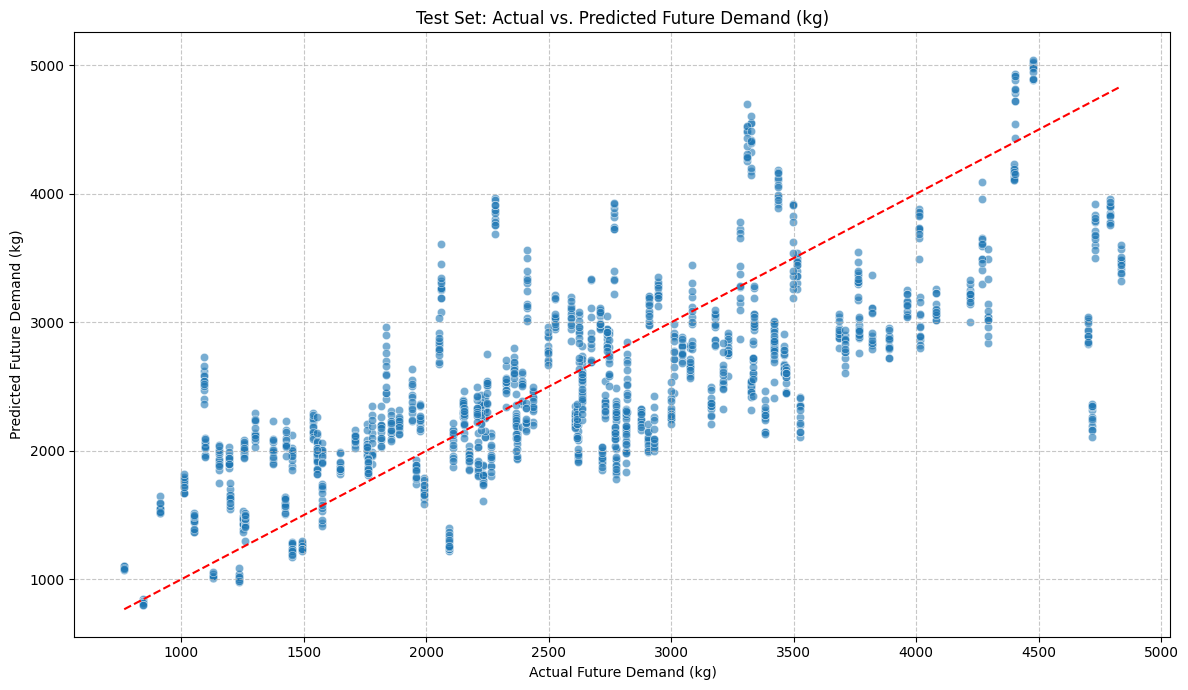

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine validation and test predictions for easier plotting if needed, or plot separately
all_predictions = pd.concat([validation_predictions, test_predictions])

# Plot 1: Actual vs. Predicted values for the Test Set
fig1 = plt.figure(figsize=(12, 7))
sns.scatterplot(x=TARGET_COLUMN, y="xgboost_prediction", data=test_predictions, alpha=0.6)
plt.title('Test Set: Actual vs. Predicted Future Demand (kg)')
plt.xlabel('Actual Future Demand (kg)')
plt.ylabel('Predicted Future Demand (kg)')
plt.plot([test_predictions[TARGET_COLUMN].min(), test_predictions[TARGET_COLUMN].max()],
         [test_predictions[TARGET_COLUMN].min(), test_predictions[TARGET_COLUMN].max()],
         'r--') # Add a diagonal line for perfect predictions
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


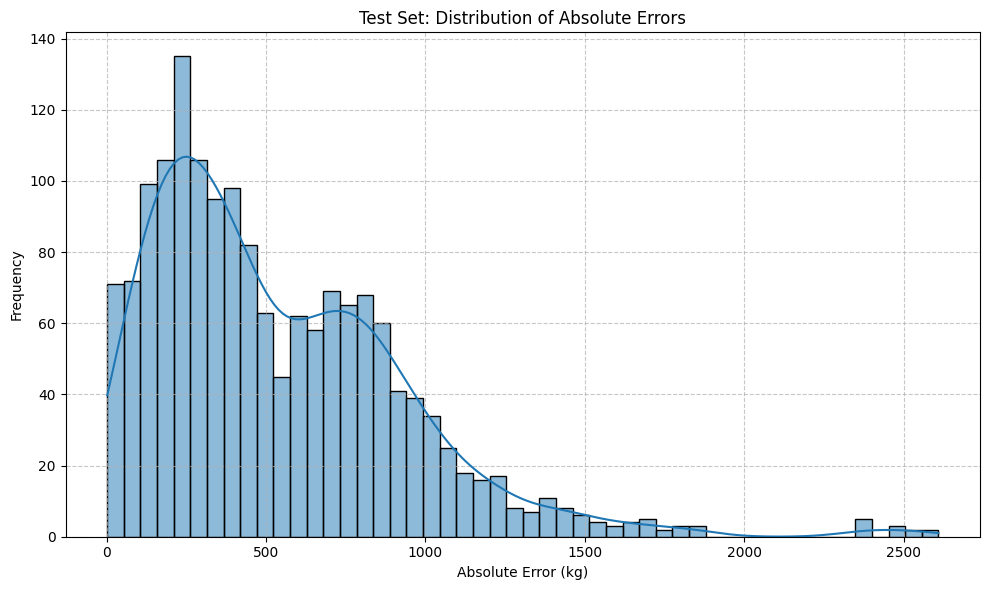

In [10]:
# Plot 2: Distribution of Absolute Errors for the Test Set
fig2 = plt.figure(figsize=(10, 6))
sns.histplot(test_predictions['absolute_error'], bins=50, kde=True)
plt.title('Test Set: Distribution of Absolute Errors')
plt.xlabel('Absolute Error (kg)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


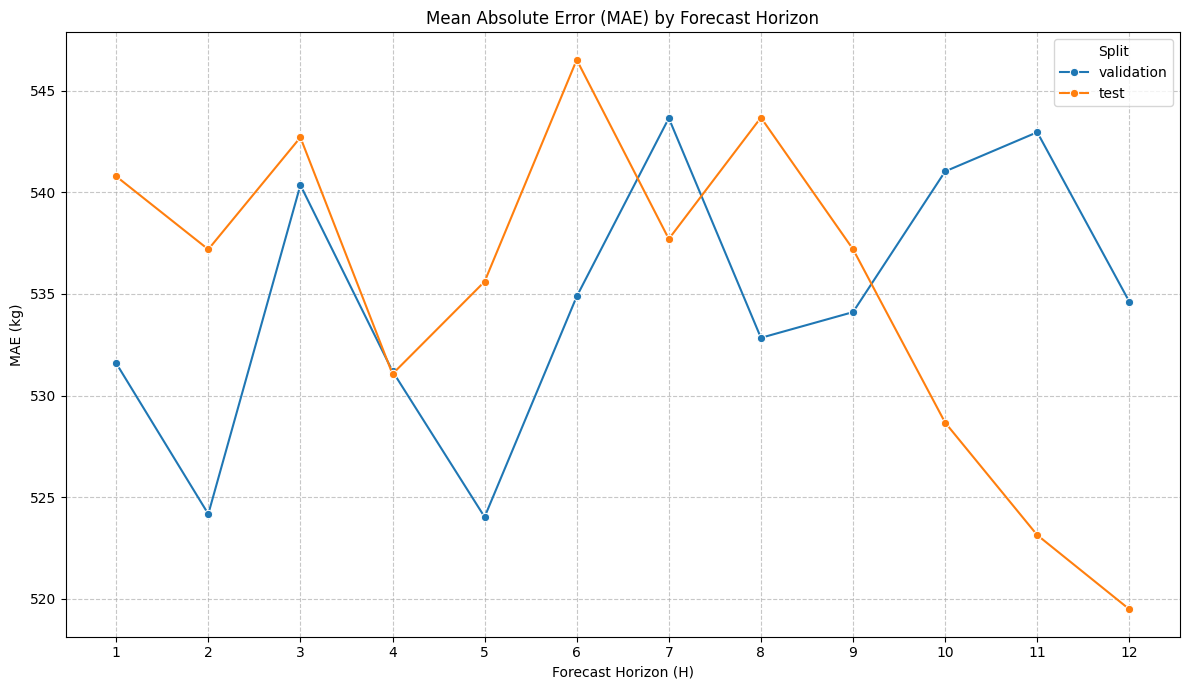

In [11]:
# Plot 3: MAE by Forecast Horizon for Validation and Test Sets
fig3 = plt.figure(figsize=(12, 7))
metrics_by_horizon = metrics[metrics['forecast_horizon'] != 'overall']
sns.lineplot(x='forecast_horizon', y='mae', hue='split', data=metrics_by_horizon, marker='o')
plt.title('Mean Absolute Error (MAE) by Forecast Horizon')
plt.xlabel('Forecast Horizon (H)')
plt.ylabel('MAE (kg)')
plt.xticks(metrics_by_horizon['forecast_horizon'].unique().astype(int)) # Ensure integer ticks
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Split')
plt.tight_layout()
plt.show()
